In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
%cd "/content/drive/MyDrive/ele680/final project"

/content/drive/MyDrive/ele680/final project


### Installation

In [5]:
!python -m pip install --upgrade "accelerate>=1.1.0"

In [6]:
!pip install transformers

#### Libraries

In [7]:
import os
import json
import numpy as np
import pandas as pd

import torch

from datasets import load_from_disk

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Imports successful")

Imports successful


### Check GPU

In [8]:
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [9]:
MODEL_NAME = "distilbert-base-uncased"

MAX_LENGTH = 128

OUTPUT_DIR = "results/erm_distilbert"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

print("Model:", MODEL_NAME)
print("Output:", OUTPUT_DIR)

Model: distilbert-base-uncased
Output: results/erm_distilbert


### Load the tokenized data

In [10]:
train_dataset = load_from_disk(
    "data/processed/tokenized_train"
)

val_dataset = load_from_disk(
    "data/processed/tokenized_validation"
)

test_dataset = load_from_disk(
    "data/processed/tokenized_test"
)

print(train_dataset)
print(val_dataset)
print(test_dataset)

Dataset({
    features: ['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 267516
})
Dataset({
    features: ['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 45047
})
Dataset({
    features: ['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'ins

In [11]:
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 267516
Validation: 45047
Test: 132730


In [12]:
print(train_dataset.column_names)
print(val_dataset.column_names)
print(test_dataset.column_names)

['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label', 'input_ids', 'token_type_ids', 'attention_mask']
['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label', 'input_ids', 'token_type_ids', 'attention_mask']
['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label', 'input_ids', 'token_type_ids', 'attention_mask']


In [13]:
example = train_dataset[0]

print("Label:")
print(example["label"])

print("\nInput IDs:")
print(example["input_ids"][:20])

print("\nAttention mask:")
print(example["attention_mask"][:20])

Label:
0

Input IDs:
[101, 100, 102]

Attention mask:
[1, 1, 1]


In [14]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [15]:
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

In [16]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

print("Model loaded")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded


In [17]:
##Accuracy, Precision, Recall, F1
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(
        logits,
        axis=-1
    )

    return {
        "accuracy": accuracy_score(
            labels,
            predictions
        ),

        "precision": precision_score(
            labels,
            predictions,
            zero_division=0
        ),

        "recall": recall_score(
            labels,
            predictions,
            zero_division=0
        ),

        "f1": f1_score(
            labels,
            predictions,
            zero_division=0
        )
    }

In [18]:
training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,

    learning_rate=2e-5,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,

    num_train_epochs=3,

    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,

    metric_for_best_model="f1",
    greater_is_better=True,

    logging_steps=100,

    report_to="none",

    seed=42
)

### Create the Trainer

In [19]:
trainer = Trainer(
    model=model,
    args=training_args,

    train_dataset=train_dataset,
    eval_dataset=val_dataset,

    processing_class=tokenizer,

    data_collator=data_collator,

    compute_metrics=compute_metrics
)

In [20]:
small_train = train_dataset.select(
    range(min(2000, len(train_dataset)))
)

small_val = val_dataset.select(
    range(min(500, len(val_dataset)))
)

In [21]:
test_trainer = Trainer(
    model=model,
    args=training_args,

    train_dataset=small_train,
    eval_dataset=small_val,

    processing_class=tokenizer,

    data_collator=data_collator,

    compute_metrics=compute_metrics
)

In [22]:
test_trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.427406,0.322308,0.864000,0.800000,0.279070,0.413793
2,0.304154,0.361350,0.876000,0.875000,0.325581,0.474576
3,0.224364,0.342272,0.886000,0.808511,0.441860,0.571429


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=375, training_loss=0.2901134796142578, metrics={'train_runtime': 102.1589, 'train_samples_per_second': 58.732, 'train_steps_per_second': 3.671, 'total_flos': 198175367995584.0, 'train_loss': 0.2901134796142578, 'epoch': 3.0})

In [23]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.199355,0.191846,0.921904,0.666010,0.604092,0.633542
2,0.166798,0.197249,0.926965,0.732533,0.545689,0.625455
3,0.138578,0.276062,0.922059,0.666230,0.606277,0.634841


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=50160, training_loss=0.16551227313859992, metrics={'train_runtime': 9709.073, 'train_samples_per_second': 82.66, 'train_steps_per_second': 5.166, 'total_flos': 2.651286964667827e+16, 'train_loss': 0.16551227313859992, 'epoch': 3.0})

### Evaluate on validation

In [24]:
val_results = trainer.evaluate(
    val_dataset
)

val_results

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.138578,0.276062,3,0.922059,0.666230,0.606277,0.634841


{'eval_loss': 0.2760617434978485,
 'eval_accuracy': 0.9220591826314738,
 'eval_precision': 0.6662300807683912,
 'eval_recall': 0.6062773142630116,
 'eval_f1': 0.6348413936557462}

### Test Prediction

In [25]:
test_output = trainer.predict(
    test_dataset
)
test_logits = test_output.predictions
test_predictions = np.argmax(
    test_logits,
    axis=-1
)

In [26]:
test_labels = np.array(
    test_dataset["label"]
)

In [27]:
test_metrics = {
    "accuracy": accuracy_score(
        test_labels,
        test_predictions
    ),

    "precision": precision_score(
        test_labels,
        test_predictions,
        zero_division=0
    ),

    "recall": recall_score(
        test_labels,
        test_predictions,
        zero_division=0
    ),

    "f1": f1_score(
        test_labels,
        test_predictions,
        zero_division=0
    )
}

test_metrics

{'accuracy': 0.9214796956226927,
 'precision': 0.6696435054091339,
 'recall': 0.610997018880424,
 'f1': 0.6389774144381322}

In [28]:
print(
    classification_report(
        test_labels,
        test_predictions,
        target_names=[
            "Non-Toxic",
            "Toxic"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

   Non-Toxic       0.95      0.96      0.96    117635
       Toxic       0.67      0.61      0.64     15095

    accuracy                           0.92    132730
   macro avg       0.81      0.79      0.80    132730
weighted avg       0.92      0.92      0.92    132730



In [29]:
cm = confusion_matrix(
    test_labels,
    test_predictions
)

print(cm)

[[113085   4550]
 [  5872   9223]]


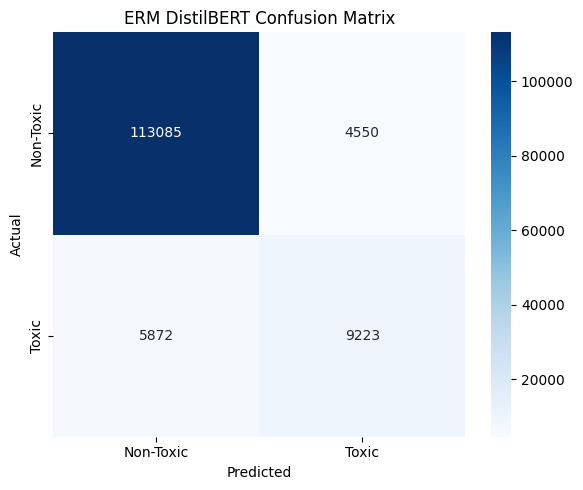

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Non-Toxic",
        "Toxic"
    ],
    yticklabels=[
        "Non-Toxic",
        "Toxic"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "ERM DistilBERT Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [31]:
prediction_df = test_dataset.to_pandas()

In [32]:
prediction_df["true_label"] = test_labels
prediction_df["prediction"] = test_predictions

In [33]:
from scipy.special import softmax

probabilities = softmax(
    test_logits,
    axis=1
)

prediction_df["prob_non_toxic"] = probabilities[:, 0]
prediction_df["prob_toxic"] = probabilities[:, 1]

In [34]:
prediction_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "test_predictions.csv"
    ),
    index=False
)

print("Predictions saved")

Predictions saved


In [35]:
with open(
    os.path.join(
        OUTPUT_DIR,
        "test_metrics.json"
    ),
    "w"
) as f:

    json.dump(
        test_metrics,
        f,
        indent=4
    )

In [36]:
trainer.save_model(
    os.path.join(
        OUTPUT_DIR,
        "best_model"
    )
)

tokenizer.save_pretrained(
    os.path.join(
        OUTPUT_DIR,
        "best_model"
    )
)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('results/erm_distilbert/best_model/tokenizer_config.json',
 'results/erm_distilbert/best_model/tokenizer.json')